# Economic Divergence and Inequality in India
**Question:** are India's richer and poorer states moving closer together, or further apart?

**Data:** Reserve Bank of India, Handbook of Statistics on Indian States, Table 10: Per Capita Net State Domestic Product, state-wise, at constant prices (₹), 2001-02 to 2025-26, split into three base years (1999-2000, 2004-05, 2011-12). You only need the RBI Table 10 Excel file.

**Plan:** (1) load the table, (2) measure inequality across states for every year, (3) test whether poorer states are catching up, (4) look at Bihar, Chhattisgarh, Goa, Gujarat and Haryana in detail.

**How to run:** click **Runtime, then Run all**. When the first cell shows a **Choose files** button, select the RBI Excel file. The rest runs by itself.

## Step 1: Load the data
This cell makes two folders (`data` and `figures`), then looks for the RBI Table 10 Excel file. If you have already uploaded it in the Files panel on the left, it uses that. If not, a **Choose files** button appears, so just select the RBI Excel file. The cell then reads all three sheets of the workbook into one table called `df` with four columns: `base` (which base year), `year`, `state`, `pc_nsdp` (per capita NSDP in rupees). A blank value means the RBI table had a dot there (not available). The printout should match the line that says "Expected".

In [1]:
import os
import openpyxl, pandas as pd

os.makedirs("data", exist_ok=True)
os.makedirs("figures", exist_ok=True)

def find_excel():
    names = [f for f in os.listdir(".") if f.lower().endswith((".xlsx", ".xls"))]
    if os.path.isdir("data/raw"):
        names += ["data/raw/" + f for f in os.listdir("data/raw") if f.lower().endswith((".xlsx", ".xls"))]
    return names

found = find_excel()
if not found:                                  # nothing uploaded yet, so ask for the RBI file
    from google.colab import files
    print("Click 'Choose files' and select the RBI Table 10 Excel file")
    files.upload()
    found = find_excel()
assert found, "No Excel file found. Upload the RBI Table 10 .xlsx file and run this cell again."
SRC = found[0]
print("Using:", SRC)

BASE_LABEL = {"1999-2000": "1999-00", "2004-05": "2004-05", "2011-12": "2011-12"}
wb = openpyxl.load_workbook(SRC, data_only=True)
rows = []
for ws in wb:                                   # three sheets, each with a different group of states
    header, base = None, None
    for r in ws.iter_rows(values_only=True):
        r = r[1:]                               # column A is empty
        first = r[0]
        if first == "State / Union Territory":
            header = list(r[1:]); continue
        if isinstance(first, str) and first.startswith("(Base"):
            base = BASE_LABEL[first.split(":")[1].strip(" )")]; continue
        if header and isinstance(first, str) and len(first) == 7 and first[4] == "-":
            for state, v in zip(header, r[1:]):
                if state is not None:
                    rows.append(dict(base=base, year=first, state=state,
                                     pc_nsdp=pd.to_numeric(v, errors="coerce")))   # "." becomes NaN

df = pd.DataFrame(rows)
df.to_csv("data/per_capita_nsdp_table10.csv", index=False)
print("years per base:", df.groupby("base").year.nunique().to_dict())
print("columns (states + All-India):", df.state.nunique(), "| missing cells:", int(df.pc_nsdp.isna().sum()))
print("Expected: {'1999-00': 4, '2004-05': 8, '2011-12': 15} | 34 | 23")

Click 'Choose files' and select the RBI Table 10 Excel file


Saving 10T_HBIE310720268B682995CC224C51B22FC6036E99B7D1.XLSX to 10T_HBIE310720268B682995CC224C51B22FC6036E99B7D1.XLSX
Using: 10T_HBIE310720268B682995CC224C51B22FC6036E99B7D1.XLSX
years per base: {'1999-00': 4, '2004-05': 8, '2011-12': 15}
columns (states + All-India): 34 | missing cells: 23
Expected: {'1999-00': 4, '2004-05': 8, '2011-12': 15} | 34 | 23


## Step 2: Choose which states to compare
**Major 17 states** is the main sample: the large states most people mean when they compare Indian states. **Broad 28** adds the smaller states. Telangana is left out because it did not exist before 2014 and has no data before 2011-12. The four Union Territories (Delhi, Chandigarh, Puducherry, Andaman and Nicobar) are left out because they are city-like or tiny. We also run the analysis without Goa and Sikkim, which are very small and very rich, to see whether a few outliers drive the result. The **First 11** group is the first eleven states in the RBI table (Andhra Pradesh to Jharkhand).

In [2]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

df = pd.read_csv("data/per_capita_nsdp_table10.csv")
BASES = ["1999-00", "2004-05", "2011-12"]
ALL_INDIA = "All-India per capita NNI"
UTS = ["Andaman & Nicobar Islands", "Chandigarh", "Delhi", "Puducherry"]

def wide(b, states=None):
    w = df[df.base == b].pivot(index="year", columns="state", values="pc_nsdp")
    return w if states is None else w[states]

india = {b: wide(b)[ALL_INDIA] for b in BASES}
STATES = [s for s in df.state.unique() if s != ALL_INDIA and s not in UTS]       # 28 states + J&K = 29
FIRST11 = ["Andhra Pradesh","Arunachal Pradesh","Assam","Bihar","Chhattisgarh","Goa","Gujarat","Haryana",
           "Himachal Pradesh","Jammu & Kashmir","Jharkhand"]
MAJOR17 = ["Andhra Pradesh","Assam","Bihar","Chhattisgarh","Gujarat","Haryana","Jharkhand","Karnataka","Kerala",
           "Madhya Pradesh","Maharashtra","Odisha","Punjab","Rajasthan","Tamil Nadu","Uttar Pradesh","West Bengal"]
BROAD = [s for s in STATES if s != "Telangana"]        # Telangana has no data before 2011-12 (formed 2014)
SAMPLES = {
    "Major 17 states (main)": MAJOR17,
    "Broad 28 (all with full history)": BROAD,
    "Broad 28 excl. Goa & Sikkim": [s for s in BROAD if s not in ("Goa", "Sikkim")],
    "First 11 (screenshot set)": FIRST11,
    "First 11 excl. Goa": [s for s in FIRST11 if s != "Goa"],
}

## Step 3: How we measure inequality
Each function turns one year's list of state incomes into a single number that describes how unequal the states are.

**Gini coefficient:** 0 means every state has the same income, higher means more unequal.
**Coefficient of variation (CV):** the standard deviation divided by the mean.
**Standard deviation of log income:** the "sigma" used in convergence research. If it falls over time, states are converging.
**Theil index:** another inequality measure, built from the ratio of each state to the average.
**Top 5 / bottom 5 ratio:** average income of the five richest states divided by that of the five poorest.

Every state counts equally. We do not weight by population, because this table has no population data.

In [3]:
# ---------- inequality measures (unweighted across states) ----------
def gini(x):
    x = np.sort(np.asarray(x, float)); n = len(x)
    return (2*np.sum(np.arange(1, n+1)*x) / (n*x.sum())) - (n+1)/n
def cv(x):    x = np.asarray(x, float); return x.std(ddof=0)/x.mean()
def sdlog(x): return np.log(np.asarray(x, float)).std(ddof=0)          # "sigma" in convergence literature
def theil(x): x = np.asarray(x, float); r = x/x.mean(); return np.mean(r*np.log(r))
def top_bottom(x, k=5): x = np.sort(np.asarray(x, float)); return x[-k:].mean()/x[:k].mean()

def metrics(w):
    out = pd.DataFrame(index=w.index)
    out["Gini"] = w.apply(gini, axis=1);  out["CV"] = w.apply(cv, axis=1)
    out["SD_log"] = w.apply(sdlog, axis=1); out["Theil"] = w.apply(theil, axis=1)
    out["Max/Min"] = w.max(axis=1)/w.min(axis=1); out["Top5/Bottom5"] = w.apply(top_bottom, axis=1)
    return out

## Step 4: Joining the three base years, and the main analysis function
The RBI table changes its base year twice, and numbers from different base years cannot be compared directly. So we do two things. First, we measure inequality **inside** each base year separately. Second, to get one long picture, `splice` joins the series using each state's own growth rates at the years where two series overlap (2004-05 and 2011-12). This gives all years in 2011-12 prices. It is a standard method but only approximate.

`run_sample` does the whole analysis for one group of states: inequality for every year, trends over time, the convergence test (do states with low starting income grow faster?), and whether the same states stay at the top and bottom. This cell only defines functions, so it prints nothing.

In [4]:
# ---------- splice the three base series into one (2011-12 prices) ----------
def splice(w1, w2, w3):
    sp = pd.DataFrame(index=list(w1.index[:-1]) + list(w2.index[:-1]) + list(w3.index), columns=w3.columns, dtype=float)
    sp.loc[w3.index] = w3
    f2 = w3.loc["2011-12"]/w2.loc["2011-12"]
    for y in w2.index[:-1]: sp.loc[y] = w2.loc[y]*f2
    f1 = sp.loc["2004-05"]/w1.loc["2004-05"]
    for y in w1.index[:-1]: sp.loc[y] = w1.loc[y]*f1
    return sp.sort_index()

def spliced_for(cols):
    return splice(*[wide(b, cols) for b in BASES])

def trend(m, k):
    r = stats.linregress(np.arange(len(m)), m[k]); return r.slope, r.pvalue

def run_sample(name, cols):
    print(f"\n{'='*92}\nSAMPLE: {name}  (n={len(cols)})\n{'='*92}")
    res = {"cols": cols}
    seg = {}
    for b in BASES:
        w = wide(b, cols).dropna()                                 # complete cross-sections only
        seg[b] = metrics(w)
        m = seg[b]
        print(f"Base {b}: years {m.index[0]}..{m.index[-1]} | Gini {m.Gini.iloc[0]:.3f}->{m.Gini.iloc[-1]:.3f} "
              f"(slope {trend(m,'Gini')[0]:+.4f}, p={trend(m,'Gini')[1]:.3f}) | "
              f"SD_log {m.SD_log.iloc[0]:.3f}->{m.SD_log.iloc[-1]:.3f} (slope {trend(m,'SD_log')[0]:+.4f}, p={trend(m,'SD_log')[1]:.3f})"
              f" | CV {m.CV.iloc[0]:.3f}->{m.CV.iloc[-1]:.3f} (slope {trend(m,'CV')[0]:+.4f}, p={trend(m,'CV')[1]:.3f})")
    res["seg"] = seg
    sp = spliced_for(cols); res["sp_all"] = sp
    sp = sp.dropna(); res["sp"] = sp
    m = metrics(sp); res["sp_m"] = m
    print(f"Spliced {sp.index[0]}..{sp.index[-1]} ({len(sp)} yrs):")
    for k in ["Gini", "CV", "SD_log", "Theil", "Top5/Bottom5", "Max/Min"]:
        s, p = trend(m, k)
        print(f"   {k:13s} {m[k].iloc[0]:7.3f} -> {m[k].iloc[-1]:7.3f}   slope/yr {s:+.5f}  p={p:.4f}")
    # beta convergence on spliced full period
    n = len(sp) - 1
    g = ((sp.iloc[-1]/sp.iloc[0])**(1/n) - 1)*100
    r = stats.linregress(np.log(sp.iloc[0]), g)
    print(f"   BETA (spliced growth vs ln initial): slope {r.slope:+.3f}  p={r.pvalue:.3f}  R2={r.rvalue**2:.2f}")
    res["beta"] = r; res["g"] = g
    # rank persistence
    rho, prho = stats.spearmanr(sp.iloc[0], sp.iloc[-1])
    top0 = set(sp.iloc[0].nlargest(5).index); top1 = set(sp.iloc[-1].nlargest(5).index)
    bot0 = set(sp.iloc[0].nsmallest(5).index); bot1 = set(sp.iloc[-1].nsmallest(5).index)
    print(f"   Rank persistence: Spearman {rho:.2f}; top-5 in both years {sorted(top0 & top1)}; bottom-5 in both {sorted(bot0 & bot1)}")
    res["rank"] = (rho, top0, top1, bot0, bot1)
    # per-base beta
    for b in BASES:
        w = wide(b, cols).dropna(); nn = len(w) - 1
        gg = ((w.iloc[-1]/w.iloc[0])**(1/nn) - 1)*100
        rr = stats.linregress(np.log(w.iloc[0]), gg)
        print(f"   beta base {b} ({nn} yrs): {rr.slope:+.3f} (p={rr.pvalue:.3f})")
    return res

## Step 5: Run the analysis for every group of states
This is the main result. For each sample, read the printout like this:

**Gini or SD_log going up** over time means the gap is widening.
**BETA slope below zero** would mean poorer states grow faster (catching up). A slope near zero or above zero means no catch-up.
**Rank persistence** shows which states stay in the top five or bottom five from 2001-02 to the end.

Look at the Major 17 block first, then check whether the other samples tell the same story.

In [5]:
R = {k: run_sample(k, v) for k, v in SAMPLES.items()}


SAMPLE: Major 17 states (main)  (n=17)
Base 1999-00: years 2001-02..2004-05 | Gini 0.197->0.205 (slope +0.0020, p=0.365) | SD_log 0.379->0.394 (slope +0.0057, p=0.113) | CV 0.348->0.360 (slope +0.0028, p=0.466)
Base 2004-05: years 2004-05..2011-12 | Gini 0.205->0.239 (slope +0.0041, p=0.003) | SD_log 0.408->0.453 (slope +0.0046, p=0.073) | CV 0.360->0.422 (slope +0.0072, p=0.003)
Base 2011-12: years 2011-12..2024-25 | Gini 0.227->0.254 (slope +0.0020, p=0.000) | SD_log 0.449->0.503 (slope +0.0043, p=0.000) | CV 0.399->0.449 (slope +0.0036, p=0.000)
Spliced 2001-02..2024-25 (24 yrs):
   Gini            0.194 ->   0.254   slope/yr +0.00271  p=0.0000
   CV              0.341 ->   0.449   slope/yr +0.00491  p=0.0000
   SD_log          0.395 ->   0.503   slope/yr +0.00483  p=0.0000
   Theil           0.061 ->   0.104   slope/yr +0.00197  p=0.0000
   Top5/Bottom5    2.358 ->   3.110   slope/yr +0.03307  p=0.0000
   Max/Min         4.916 ->   5.760   slope/yr +0.04938  p=0.0000
   BETA (spli

## Step 6: Comparing with the all-India average, and how fast each state grew
First we build an all-India series (joined across base years in the same way). Then we calculate each state's average yearly growth rate (CAGR) for each base year and for the full period 2001-02 to 2024-25. Nagaland has no 2024-25 value, so its growth is measured to 2023-24. The last line shows where Bihar, Chhattisgarh, Gujarat, Haryana and Goa rank among the 28 states.

In [6]:
# ---------- all-India benchmark, spliced ----------
ind_sp = splice(*[india[b].to_frame("India") for b in BASES])["India"].dropna()
sp_all = spliced_for(BROAD)                                         # every state with full history, all years
sp_all_full = sp_all.dropna(how="all")

# ---------- growth velocity (common end year 2024-25; Nagaland only reports to 2023-24) ----------
END = "2024-25"
rows = []
for st in BROAD:
    r = dict(state=st)
    for b in BASES:
        s = wide(b)[st].dropna(); r[f"CAGR {b}"] = ((s.iloc[-1]/s.iloc[0])**(1/(len(s)-1)) - 1)*100
    s = sp_all[st].dropna(); s = s.loc[:END]
    r["Spliced start"] = s.iloc[0]; r["Spliced end"] = s.iloc[-1]; r["End year"] = s.index[-1]
    r["CAGR spliced"] = ((s.iloc[-1]/s.iloc[0])**(1/(len(s)-1)) - 1)*100; r["Multiple"] = s.iloc[-1]/s.iloc[0]
    rows.append(r)
gv = pd.DataFrame(rows).set_index("state").sort_values("CAGR spliced", ascending=False)
print("\n=== Growth velocity, % p.a. (spliced 2001-02 to 2024-25; Nagaland to 2023-24) ===\n", gv.round(2).to_string())
gv.round(3).to_csv("data/growth_velocity.csv")
print("Rank of Bihar / Chhattisgarh / Gujarat / Haryana / Goa by spliced CAGR (of 28):",
      {k: int(gv["CAGR spliced"].rank(ascending=False)[k]) for k in ["Bihar","Chhattisgarh","Gujarat","Haryana","Goa"]}, "| median CAGR", round(gv["CAGR spliced"].median(),2))


=== Growth velocity, % p.a. (spliced 2001-02 to 2024-25; Nagaland to 2023-24) ===
                    CAGR 1999-00  CAGR 2004-05  CAGR 2011-12  Spliced start  Spliced end End year  CAGR spliced  Multiple
state                                                                                                                   
Sikkim                     6.61         15.62          5.12       47414.34     303797.0  2024-25          8.41      6.41
Gujarat                    8.65          8.49          6.97       38559.40     208895.0  2024-25          7.62      5.42
Mizoram                    3.11          6.34          8.53       34204.83     167121.0  2024-25          7.14      4.89
Tamil Nadu                 5.17          9.60          6.28       42141.33     197747.0  2024-25          6.95      4.69
Uttarakhand                8.31         11.39          3.66       37103.56     156165.0  2024-25          6.45      4.21
Tripura                    5.37          7.17          6.30       248

## Step 7: Who is catching up, who is falling behind
This cell shows each state as a percentage of the all-India figure, and Bihar and Chhattisgarh compared with the 17-state average, Gujarat and Haryana. It also prints the rupee gap between Bihar and the two leaders, the growth of each state in 2025-26 (only some states report it), and a few details about Goa's ups and downs.

In [7]:
# ---------- relative position vs All-India ----------
sp_c = sp_all[["Goa","Gujarat","Haryana","Bihar","Chhattisgarh","Uttar Pradesh","Maharashtra","Tamil Nadu","Karnataka","Kerala"]].dropna()
rel = sp_c.div(ind_sp.reindex(sp_c.index), axis=0)*100
print("\n=== State as % of All-India per capita NNI (spliced) ===\n", rel.iloc[[0,5,10,15,-1]].round(1).T.to_string())
sp17 = R["Major 17 states (main)"]["sp"]
rel17 = pd.DataFrame({"Bihar % of 17-state mean": sp17["Bihar"]/sp17.mean(axis=1)*100,
                      "Chhattisgarh % of 17-state mean": sp17["Chhattisgarh"]/sp17.mean(axis=1)*100,
                      "Bihar % of Gujarat": sp17["Bihar"]/sp17["Gujarat"]*100,
                      "Bihar % of Haryana": sp17["Bihar"]/sp17["Haryana"]*100,
                      "Chhattisgarh % of Gujarat": sp17["Chhattisgarh"]/sp17["Gujarat"]*100,
                      "Chhattisgarh % of Haryana": sp17["Chhattisgarh"]/sp17["Haryana"]*100})
print("\n=== Relative position within Major 17 ===\n", rel17.iloc[[0,5,10,15,-1]].round(1).to_string())
rel.round(2).to_csv("data/relative_to_all_india.csv"); rel17.round(2).to_csv("data/relative_position_major17.csv")
gap = pd.DataFrame({"Gujarat-Bihar": sp17["Gujarat"]-sp17["Bihar"], "Haryana-Bihar": sp17["Haryana"]-sp17["Bihar"]})
print("\nAbsolute gaps Rs (2011-12 prices), first/last:\n", gap.iloc[[0,-1]].round(0).to_string())
goa_bihar = (sp_all["Goa"]/sp_all["Bihar"]).loc[:END]; print("Goa/Bihar ratio first/last:", round(goa_bihar.iloc[0],1), round(goa_bihar.iloc[-1],1))

# 2025-26 snapshot
w3 = wide("2011-12"); g2526 = ((w3.loc["2025-26"]/w3.loc["2024-25"] - 1)*100).dropna().round(1)
print("\n2025-26 growth over 2024-25 (states reporting):\n", g2526.to_string())
print("Goa 2011-12..2015-16:", w3["Goa"].iloc[:5].tolist(), "| 2020-21 vs 2019-20 % chg (Bihar, Haryana, Goa):",
      ((w3.loc["2020-21"]/w3.loc["2019-20"] - 1)*100).round(1)[["Bihar","Haryana","Goa"]].to_dict())


=== State as % of All-India per capita NNI (spliced) ===
                2001-02  2006-07  2011-12  2016-17  2024-25
state                                                     
Goa              382.8    369.4    408.8    368.5    298.5
Gujarat          110.4    127.3    137.8    156.3    182.1
Haryana          156.1    163.1    167.2    181.0    169.4
Bihar             33.2     30.9     34.3     30.7     31.6
Chhattisgarh      93.6     93.6     86.9     80.9     81.9
Uttar Pradesh     62.4     55.1     51.4     50.8     50.3
Maharashtra      140.4    158.3    156.9    161.1    158.3
Tamil Nadu       120.6    136.4    146.7    148.4    172.4
Karnataka        146.8    148.5    142.2    158.0    181.7
Kerala           141.2    150.9    154.3    155.7    151.5

=== Relative position within Major 17 ===
          Bihar % of 17-state mean  Chhattisgarh % of 17-state mean  Bihar % of Gujarat  Bihar % of Haryana  Chhattisgarh % of Gujarat  Chhattisgarh % of Haryana
2001-02                     

## Step 8: Save the result tables
The year-by-year inequality results and the joined income series are saved as CSV files in the `data` folder.

In [8]:
# ---------- save tables ----------
out = pd.concat({k: v["sp_m"] for k, v in R.items()}, axis=1); out.round(4).to_csv("data/spliced_inequality_by_sample.csv")
seg_rows = []
for k, v in R.items():
    for b in BASES:
        m = v["seg"][b].copy(); m.insert(0, "base", b); m.insert(0, "sample", k); seg_rows.append(m.reset_index(names="year"))
pd.concat(seg_rows).round(4).to_csv("data/inequality_within_base.csv", index=False)
sp_all_full.round(0).to_csv("data/spliced_per_capita_nsdp_28_states.csv")

## Step 9: Make the charts
Six charts are saved in the `figures` folder:
1. Inequality inside each base year (Major 17)
2. Inequality over the full period, three samples
3. Income levels of rich and poor states on a log scale
4. The convergence test as a scatter plot
5. Bihar, Chhattisgarh and Uttar Pradesh compared with the all-India average
6. Growth speed of all 28 states

In [9]:
# ---------- figures ----------
plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
C = {"Goa":"#b8860b","Gujarat":"#c0392b","Haryana":"#e67e22","Bihar":"#1f4e79","Chhattisgarh":"#2e86c1"}
main = R["Major 17 states (main)"]; broad = R["Broad 28 (all with full history)"]; first11 = R["First 11 (screenshot set)"]

fig, ax = plt.subplots(1, 3, figsize=(12, 3.6))
for a_, k, t in zip(ax, ["Gini", "CV", "SD_log"], ["Gini coefficient", "Coefficient of variation", "Std. dev. of ln(per-capita NSDP)"]):
    for b, c in zip(BASES, ["#7f8c8d", "#2c3e50", "#c0392b"]):
        m = main["seg"][b]; a_.plot(m.index, m[k], marker="o", ms=3, color=c, label=f"base {b}")
    a_.set_title(t); a_.tick_params(axis="x", rotation=90, labelsize=6)
ax[0].legend(frameon=False, fontsize=7)
fig.suptitle("Major 17 states: inequality within each base series (levels are NOT comparable across bases)", fontsize=9)
fig.tight_layout(); fig.savefig("figures/01_inequality_by_base.png"); plt.close()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for key, col, lab in [("Major 17 states (main)", "#c0392b", "Major 17"), ("Broad 28 (all with full history)", "#2c3e50", "Broad 28"),
                      ("Broad 28 excl. Goa & Sikkim", "#16a085", "Broad 28 excl. Goa & Sikkim")]:
    m = R[key]["sp_m"]
    ax[0].plot(m.index, m.Gini, marker="o", ms=3, color=col, label=lab); ax[1].plot(m.index, m.SD_log, marker="o", ms=3, color=col, label=lab)
for a_, t in zip(ax, ["Gini", "Std. dev. of ln(per-capita NSDP)  (sigma)"]):
    a_.set_title(t + ", spliced to 2011-12 prices"); a_.tick_params(axis="x", rotation=90, labelsize=7)
    for c in ["2004-05", "2011-12"]: a_.axvline(c, ls=":", color="grey")
ax[0].legend(frameon=False, fontsize=8); fig.tight_layout(); fig.savefig("figures/02_spliced_inequality.png"); plt.close()

fig, ax = plt.subplots(figsize=(8, 4.2))
for st in ["Goa", "Gujarat", "Haryana", "Chhattisgarh", "Bihar"]:
    s = sp_all[st].dropna(); ax.plot(s.index, s/1000, color=C[st], label=st, lw=1.8)
ax.plot(ind_sp.index, ind_sp/1000, color="black", ls="--", lw=1.2, label="All-India")
ax.set_yscale("log"); ax.set_ylabel("Rs '000 (log scale), 2011-12 prices"); ax.legend(frameon=False, ncol=6, fontsize=7, loc="upper left")
ax.tick_params(axis="x", rotation=90, labelsize=7); ax.set_title("Per-capita NSDP: high-income vs low-income states (spliced)")
fig.tight_layout(); fig.savefig("figures/03_levels_log.png"); plt.close()

sp, g, r = main["sp"], main["g"], main["beta"]
fig, ax = plt.subplots(figsize=(6.8, 4.6)); x0 = np.log(sp.iloc[0])
ax.scatter(x0, g, s=40, color="#2c3e50")
for st in sp.columns: ax.annotate(st, (x0[st], g[st]), fontsize=7, xytext=(3, 3), textcoords="offset points")
xs = np.linspace(x0.min(), x0.max(), 50); ax.plot(xs, r.intercept + r.slope*xs, "--", color="#c0392b", label=f"slope {r.slope:.2f} (p={r.pvalue:.2f})")
ax.set_xlabel("ln(per-capita NSDP in 2001-02, 2011-12 prices)"); ax.set_ylabel("CAGR 2001-02 to 2024-25 (%)"); ax.legend(frameon=False, fontsize=8)
ax.set_title("Beta-convergence test, major 17 states"); fig.tight_layout(); fig.savefig("figures/04_beta_convergence.png"); plt.close()

fig, ax = plt.subplots(figsize=(8, 3.8))
for st in ["Bihar", "Chhattisgarh", "Uttar Pradesh"]:
    ax.plot(rel.index if st in rel else sp_c.index, (sp_all[st].dropna().reindex(rel.index)/ind_sp.reindex(rel.index)*100), marker="o", ms=3, label=st,
            color=C.get(st, "#7f8c8d"))
ax.axhline(100, color="black", lw=0.8, ls="--"); ax.set_ylabel("% of All-India per-capita NNI"); ax.legend(frameon=False)
ax.tick_params(axis="x", rotation=90, labelsize=7); ax.set_title("Catching up with the national average?")
fig.tight_layout(); fig.savefig("figures/05_relative_position.png"); plt.close()

fig, ax = plt.subplots(figsize=(7.5, 7))
gs = gv["CAGR spliced"].sort_values()
cols = ["#1f4e79" if s in ("Bihar", "Chhattisgarh") else "#b8860b" if s in ("Goa", "Gujarat", "Haryana") else "#95a5a6" for s in gs.index]
ax.barh(gs.index, gs.values, color=cols); ax.set_xlabel("CAGR of real per-capita NSDP, 2001-02 to 2024-25 (%)  [Nagaland to 2023-24]")
ax.set_title("Growth velocity, 28 states (spliced)"); fig.tight_layout(); fig.savefig("figures/06_growth_velocity.png"); plt.close()
print("\nfigures saved")


figures saved


## Step 10: View the charts here
This displays the saved charts inside the notebook.

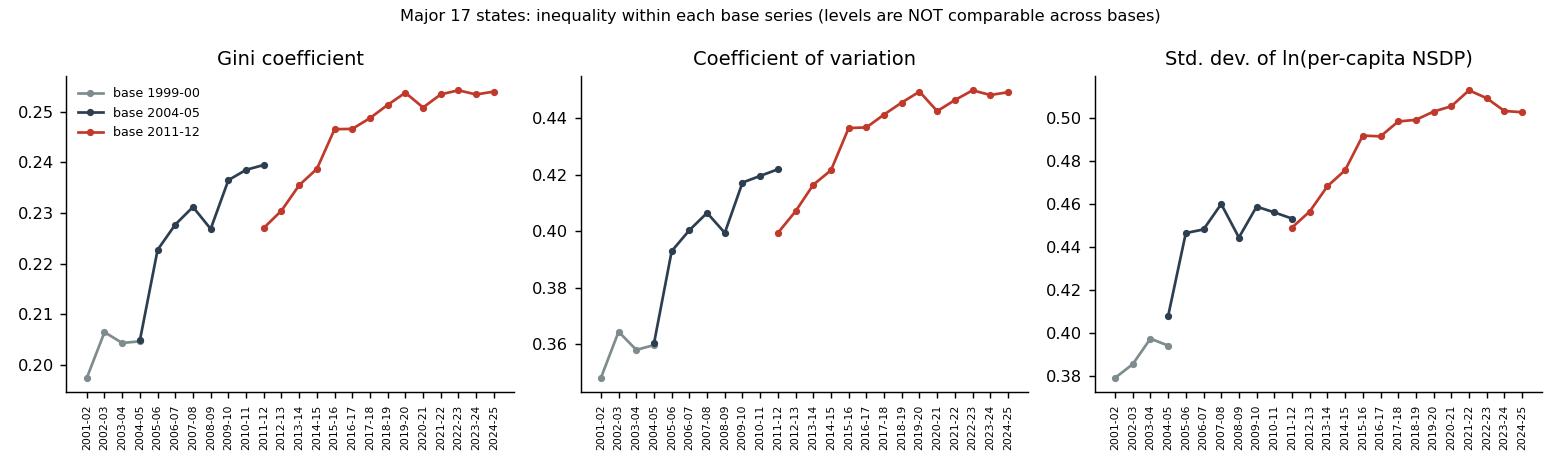

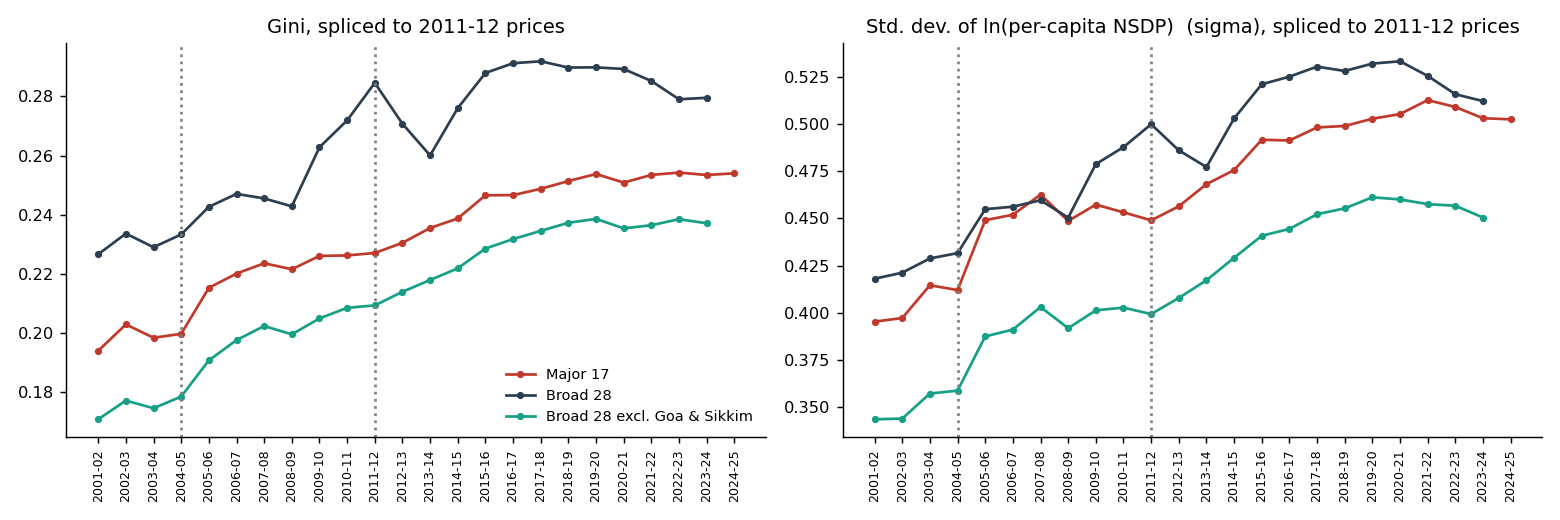

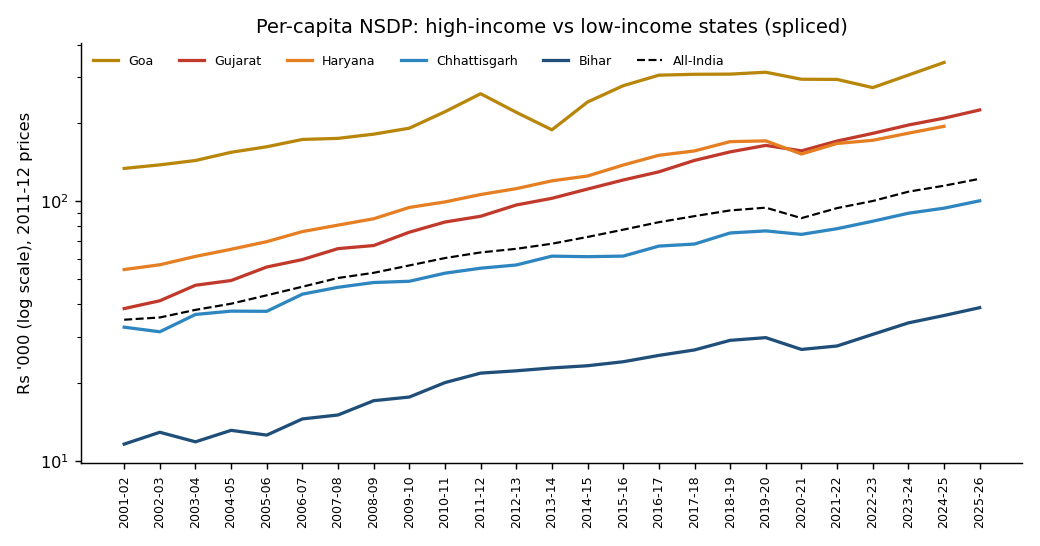

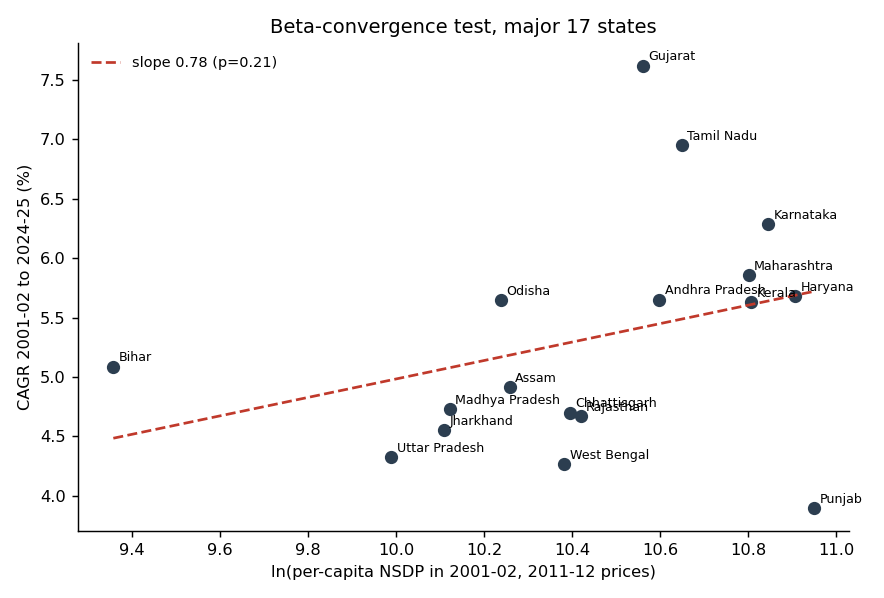

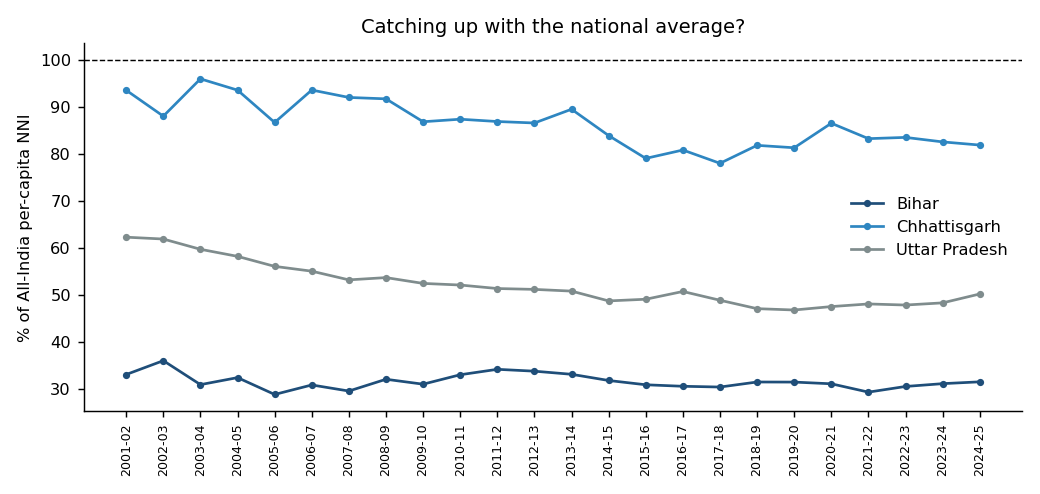

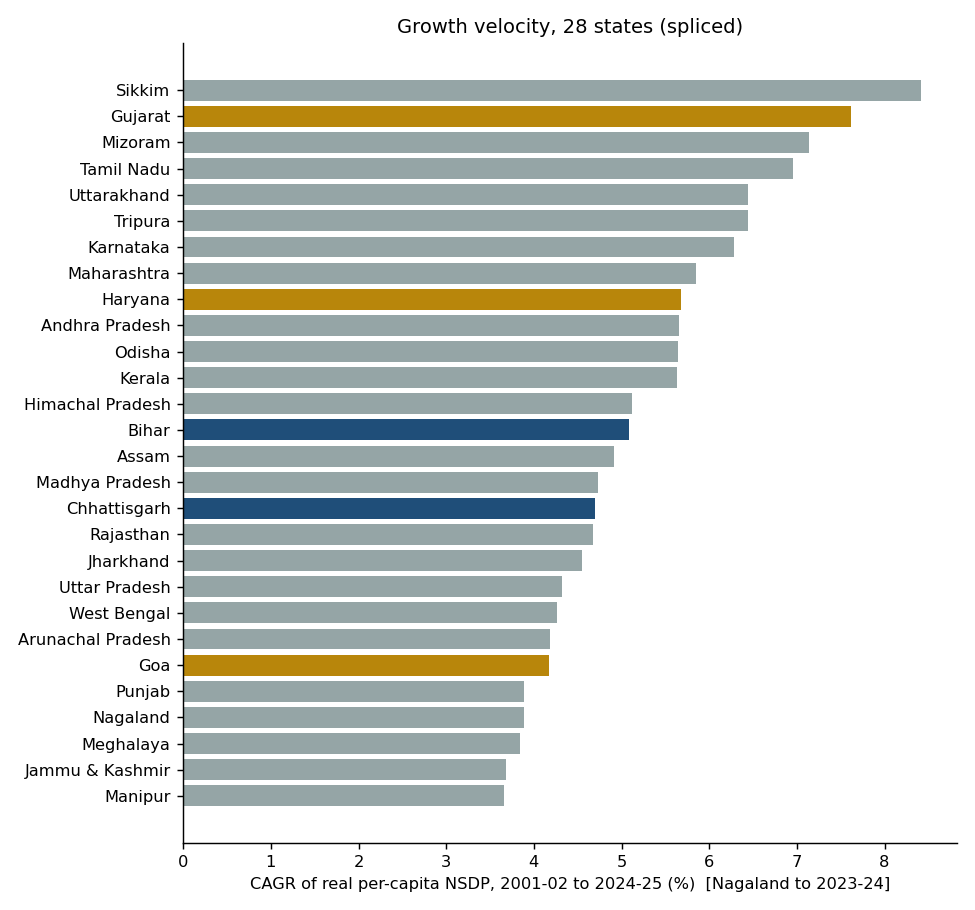

In [10]:
from IPython.display import Image, display
import glob
for f in sorted(glob.glob("figures/*.png")):
    display(Image(f))

## Step 11 (optional): Download everything
Colab deletes its files when the session ends. This cell packs the `data` and `figures` folders into one zip and downloads it to your computer.

In [11]:
!zip -r -q project_outputs.zip data figures
from google.colab import files
files.download("project_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## What the results say
Across the 17 major states, inequality rose between 2001-02 and 2024-25: the Gini went from about 0.19 to 0.25, and the other measures moved the same way. Poorer states did not grow faster than richer ones, so there is no sign of convergence. Bihar, Jharkhand, Madhya Pradesh and Uttar Pradesh stayed in the bottom five, and Gujarat pulled well ahead. Bihar kept pace with the national median but remains at about one third of the all-India average. Goa is still the richest state but its lead has shrunk.

**Keep in mind:** joining base years is an approximation, states are not weighted by population, per capita state output is not household income, and p-values for time trends look more impressive than they are.